# Proyecto 2: Clasificación de enfermedades en hojas de frijol

### Visión artificial

### Universidad de Medellín

### Facultad de Ingenierías

### Ingeniería de Sistemas

#### Curso: Procesamiento de Datos

#### Profesor: Antonio Jesús Tamayo Herrera, PhD

#### Integrantes: Juan Jose Giraldo, Alejandro Hernandez, Alejandro Marin

Este notebook resuelve un problema de **clasificación de imágenes con 3 clases**: a partir de una foto
de una hoja de frijol, decir si está sana, si tiene *Angular Leaf Spot* o si tiene *Bean Rust*. El
dataset se carga desde **TensorFlow Datasets** (`tfds.load("beans")`), se hace un análisis exploratorio
con las imágenes de cada clase y se entrenan dos redes preentrenadas en ImageNet, **VGG16** y **ResNet50**, primero con la base
congelada. El fine-tuning (descongelar el último bloque) se hace solo sobre el ganador. También se entrena una CNN
pequeña desde cero, para tener un punto de comparación y poder mover el número de filtros en una malla.
Al final se elige el mejor modelo y se evalúa en el conjunto de test oficial, que no se usa para
ajustar nada.

## 1. Importaciones y configuración

In [1]:
# Silence library warnings before importing TensorFlow, otherwise they show up in the output
import os
import warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")

# Importaciones base
import time
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# TensorFlow / Keras
import tensorflow as tf
import tensorflow_datasets as tfds
tf.get_logger().setLevel("ERROR")
tfds.disable_progress_bar()
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as preprocess_vgg
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet

# Métricas
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"GPUs visibles: {len(gpus)}")


TensorFlow: 2.21.0
GPUs visibles: 0


## 2. Carga del dataset y descripción de la base de datos

### ¿Por qué este dataset?

El catálogo de TensorFlow Datasets tiene muchos conjuntos de imágenes. Elegimos **`beans`** por tres
razones prácticas:

- Es un problema real de agricultura, no un toy dataset tipo MNIST o gatos contra perros.
- Es **pequeño** (1.295 imágenes) y **casi balanceado**, así que se puede entrenar en Colab sin
  trucos raros y las métricas no quedan distorsionadas por una clase que se come a las otras.
- Ya viene partido en train / validation / test, así que no hay que inventar el corte ni arriesgarse
  a mezclar test con entrenamiento.

Fuente en el catálogo: [beans | TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/beans).
El dataset original lo publicó el Makerere AI Lab con el National Crops Resources Research Institute
(NaCRRI) de Uganda: [ibean](https://github.com/AI-Lab-Makerere/ibean/).

In [2]:
# Load beans from TensorFlow Datasets. If the official Google bucket answers 403,
# download the same Makerere zips from the Hugging Face copy and load them with Keras.
IMG_SIZE = 224
CLASS_NAMES = ["angular_leaf_spot", "bean_rust", "healthy"]
NUM_CLASSES = 3

HF_ZIPS = {
    "train": "https://huggingface.co/datasets/beans/resolve/main/data/train.zip",
    "validation": "https://huggingface.co/datasets/beans/resolve/main/data/validation.zip",
    "test": "https://huggingface.co/datasets/beans/resolve/main/data/test.zip",
}


def _download_hf_mirror(root="beans_data"):
    import zipfile
    import urllib.request

    # Reuse a local copy if we already extracted the Makerere zips
    for candidate in (root, "/tmp/beans_data"):
        guess = {s: os.path.join(candidate, s, s) for s in ("train", "validation", "test")}
        if all(os.path.isdir(p) for p in guess.values()):
            print("Imágenes del dataset listas.")
            return guess

    os.makedirs(root, exist_ok=True)
    paths = {}
    for split, url in HF_ZIPS.items():
        dest_dir = os.path.join(root, split)
        inner = os.path.join(dest_dir, split)
        zip_path = os.path.join(root, f"{split}.zip")
        print(f"Descargando {split} desde el mirror de Hugging Face...")
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(dest_dir)
        paths[split] = inner
    return paths


def load_beans():
    try:
        (ds_train, ds_val, ds_test), info = tfds.load(
            "beans",
            split=["train", "validation", "test"],
            as_supervised=True,
            with_info=True,
        )
        names = info.features["label"].names
        print("Cargado con tensorflow_datasets.load('beans')")
        print(f"Splits: { {k: info.splits[k].num_examples for k in ['train', 'validation', 'test']} }")
        print(f"Clases: {names}")
        print(f"Imagen original: {info.features['image'].shape}")
        return ds_train, ds_val, ds_test, names, "tfds"
    except Exception as e:
        print("tfds.load no pudo bajar el zip oficial (el bucket de Google respondió 403).")
        print("Se usa el mismo dataset de Makerere, desde el mirror de Hugging Face, y Keras.")
        paths = _download_hf_mirror()
        return paths, None, None, CLASS_NAMES, "keras_dir"


loaded = load_beans()
ds_train_raw, ds_val_raw, ds_test_raw, class_names, load_mode = loaded
print(f"\nModo de carga: {load_mode}")
print(f"Clases: {class_names}")

tfds.load no pudo bajar el zip oficial (el bucket de Google respondió 403).
Se usa el mismo dataset de Makerere, desde el mirror de Hugging Face, y Keras.
Imágenes del dataset listas.

Modo de carga: keras_dir
Clases: ['angular_leaf_spot', 'bean_rust', 'healthy']


### Descripción de la base de datos

**Dominio.** Agricultura / fitopatología. Las fotos se tomaron en cultivos de frijol de distintos
distritos de Uganda, con un celular común y corriente, no en un laboratorio. Cada imagen es una
hoja. Quienes etiquetaron no fueron voluntarios de internet: fueron expertos del NaCRRI, que
anotaron la enfermedad **allí mismo, en el campo**.

**Utilidad.** El frijol es un cultivo de comida diaria en África oriental y una fuente importante
de proteína, sobre todo para niños en edad escolar. *Angular Leaf Spot* y *Bean Rust* bajan el
rendimiento si no se detectan a tiempo. Un agrónomo no puede recorrer cada parcela, y un campesino
no siempre distingue las dos enfermedades a simple vista. La idea del dataset es esta: el campesino
saca una foto con el celular y un modelo le dice qué tiene la planta, para decidir si aplica un
tratamiento, si aísla esa zona o si no hay que hacer nada.

Eso le sirve a un **extensionista agrícola o a un ministerio de agricultura** que quiere llevar
diagnóstico a fincas pequeñas sin mandar a un experto cada vez. La decisión concreta es de
**priorización**: qué lotes revisar primero y qué enfermedad tratar. El modelo no reemplaza al
fitopatólogo; ordena la fila.

**Variable de salida.** `label`, con tres valores:

| Clase | Nombre en el dataset | Qué es |
|---|---|---|
| 0 | `angular_leaf_spot` | Mancha angular de la hoja, causada por el hongo *Pseudocercospora griseola*. Manchas angulosas, a menudo delimitadas por las nervaduras. |
| 1 | `bean_rust` | Roya del frijol, causada por *Uromyces appendiculatus*. Pústulas color óxido en el envés. |
| 2 | `healthy` | Hoja sana, sin esas dos enfermedades. |

**Tipo de problema.** Clasificación de imágenes **multiclase supervisada** (3 clases, una sola
etiqueta por foto). No es detección (no hay cajas), ni segmentación (no hay máscaras), ni biclase.

**Tamaños.** 1.295 imágenes RGB de 500 × 500. El catálogo las reparte así:

| Split | Imágenes | Para qué lo usamos |
|---|---|---|
| train | 1.034 | Entrenar y ajustar hiperparámetros |
| validation | 133 | Elegir la mejor combinación de la malla |
| test | 128 | Evaluación final, una sola vez |

Las clases están casi igualadas. En nuestro conteo quedan 432 de mancha angular, 436 de roya y 427
sanas (1.295 en total). El readme original decía 428 sanas; una de esas no era una imagen y se
descartó. No hace falta balancear.

**Limitación.** Las fotos son de Uganda, de 2020, de dos enfermedades concretas y de un celular.
Un modelo que funcione aquí no tiene por qué funcionar con otra variedad de frijol, otra cámara o
otra enfermedad. Además, en el campo la hoja a veces está mojada, a contraluz o tapa solo una
parte del cuadro, y eso ya viene en los datos.

## 3. Análisis exploratorio de datos

In [3]:
# Materialize a few examples and count classes per split
def count_from_tfds(ds):
    counts = {name: 0 for name in class_names}
    for _, y in ds:
        counts[class_names[int(y.numpy())]] += 1
    return counts


def is_image(fname):
    return fname.lower().endswith((".jpg", ".jpeg", ".png"))


def count_from_dir(split_dir):
    counts = {}
    for name in class_names:
        folder = os.path.join(split_dir, name)
        counts[name] = len([f for f in os.listdir(folder) if is_image(f)])
    return counts


if load_mode == "tfds":
    counts_train = count_from_tfds(ds_train_raw)
    counts_val = count_from_tfds(ds_val_raw)
    counts_test = count_from_tfds(ds_test_raw)
else:
    paths = ds_train_raw
    counts_train = count_from_dir(paths["train"])
    counts_val = count_from_dir(paths["validation"])
    counts_test = count_from_dir(paths["test"])

rows = []
for name in class_names:
    n_tr, n_va, n_te = counts_train[name], counts_val[name], counts_test[name]
    rows.append({
        "clase": name,
        "train": n_tr,
        "validation": n_va,
        "test": n_te,
        "total": n_tr + n_va + n_te,
    })

print("Conteo de imágenes por clase y split")
for r in rows:
    print(f"{r['clase']:20s}  train={r['train']:4d}  val={r['validation']:4d}  test={r['test']:4d}  total={r['total']:4d}")

tot_tr = sum(counts_train.values())
tot_va = sum(counts_val.values())
tot_te = sum(counts_test.values())
print(f"\nTotales: train={tot_tr}  val={tot_va}  test={tot_te}  todo={tot_tr + tot_va + tot_te}")

Conteo de imágenes por clase y split
angular_leaf_spot     train= 345  val=  44  test=  43  total= 432
bean_rust             train= 348  val=  45  test=  43  total= 436
healthy               train= 341  val=  44  test=  42  total= 427

Totales: train=1034  val=133  test=128  todo=1295


### 3.1 Distribución de clases

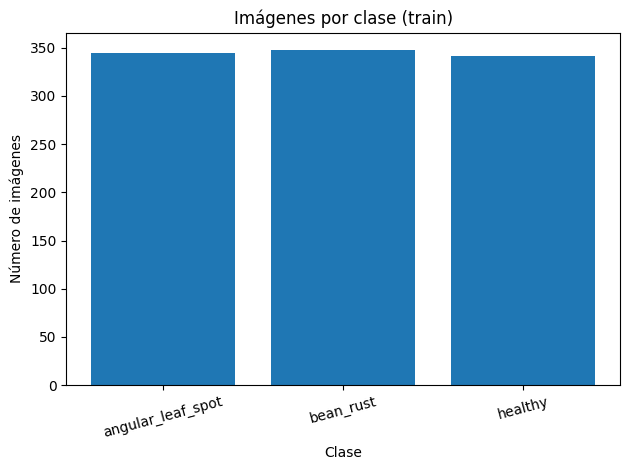

In [4]:
# Bar chart of class counts on train
plt.figure()
plt.bar(class_names, [counts_train[c] for c in class_names])
plt.title("Imágenes por clase (train)")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

En train las tres barras salen casi de la misma altura: 345, 348 y 341. Validation y test también
están repartidos parejo (44/45/44 y 43/43/42). En el total hay 1.295 fotos, una menos que las 1.296
del catálogo: en `healthy` de train apareció un archivo que no era imagen y lo descartamos.

Acá **accuracy sí sirve** como métrica principal, a diferencia del Proyecto 1, porque un modelo que
ignore una clase se nota de inmediato. Aun así reportamos F1 macro, para no esconder si una
enfermedad se confunde más que las otras.

### 3.2 Imágenes de cada clase

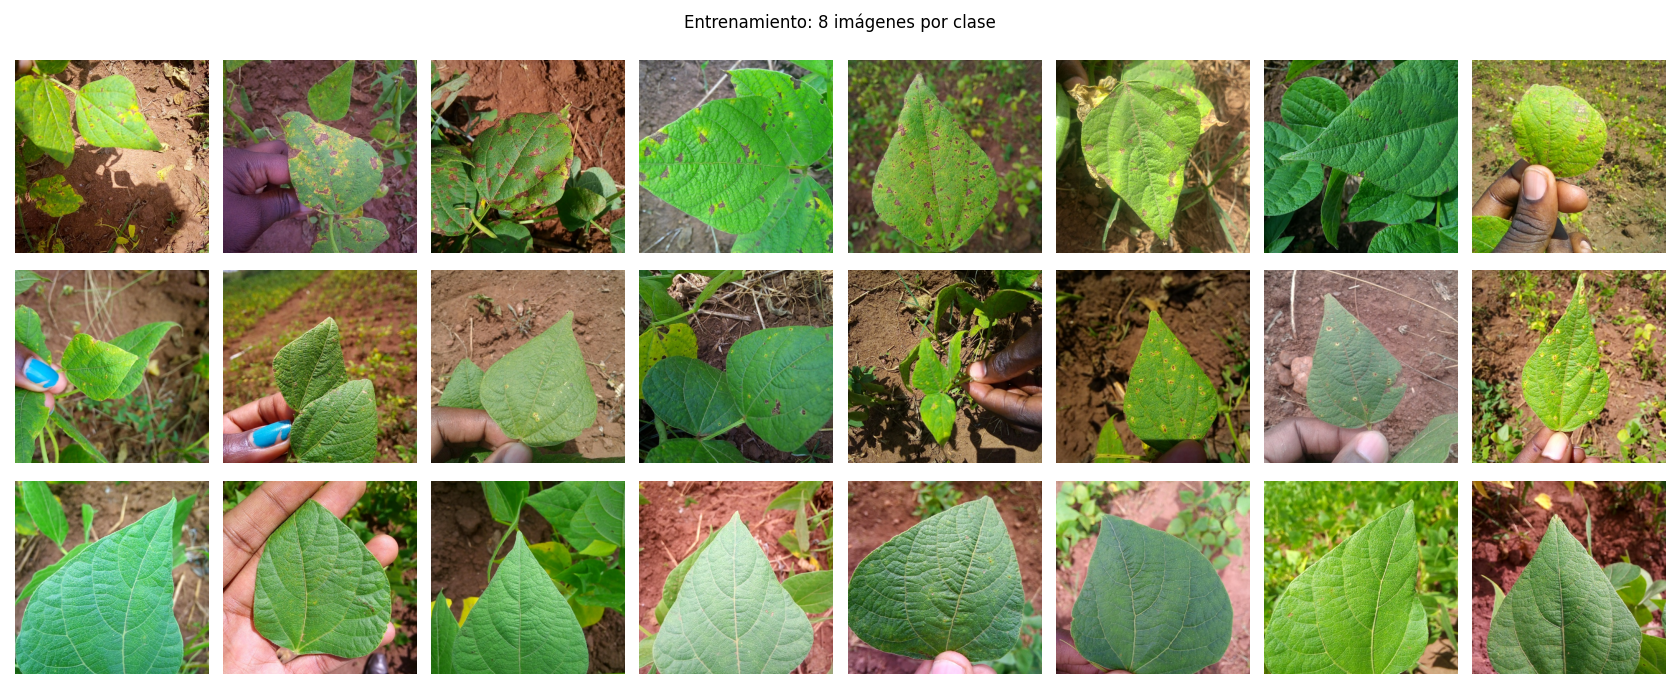

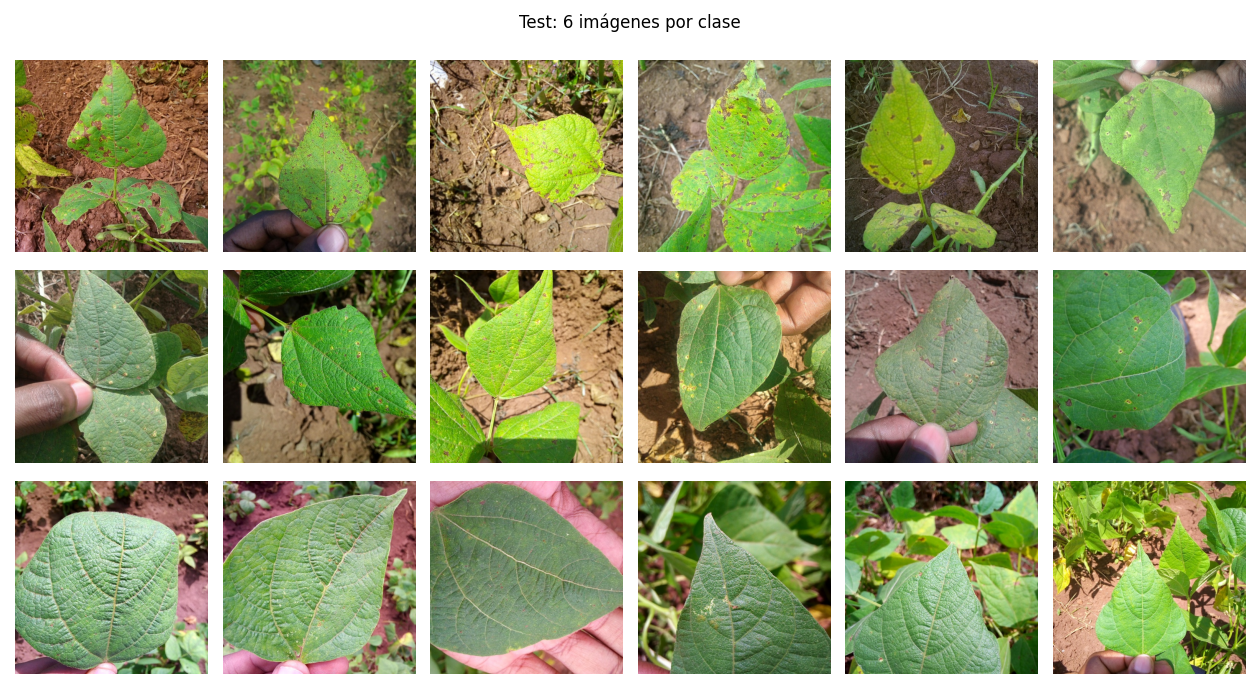

In [5]:
# Collect several raw images per class so the grid is not just three photos
def collect_examples(split_dir, n_per_class=8):
    buckets = {i: [] for i in range(NUM_CLASSES)}
    for i, name in enumerate(class_names):
        folder = os.path.join(split_dir, name)
        files = sorted([f for f in os.listdir(folder) if is_image(f)])
        for fname in files[:n_per_class]:
            with Image.open(os.path.join(folder, fname)) as im:
                buckets[i].append(np.array(im.convert("RGB")))
    return buckets


def show_examples(buckets, n_cols, title):
    fig, axes = plt.subplots(NUM_CLASSES, n_cols, figsize=(2.1 * n_cols, 7))
    for i, name in enumerate(class_names):
        for j in range(n_cols):
            axes[i, j].imshow(buckets[i][j])
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_ylabel(name, fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# 8 photos per class from train, then 6 from test
def split_folder(split):
    if load_mode == "keras_dir":
        return ds_train_raw[split]
    return os.path.join("beans_data", split, split)


train_dir = split_folder("train")
test_dir = split_folder("test")

show_examples(collect_examples(train_dir, 8), 8, "Entrenamiento: 8 imágenes por clase")
show_examples(collect_examples(test_dir, 6), 6, "Test: 6 imágenes por clase")


A simple vista las tres clases se parecen más de lo que uno quisiera: todas son hojas verdes
fotografiadas al aire libre, con fondo de tierra o de otras plantas. La diferencia está en el
**deterioro de la lámina**:

- **angular_leaf_spot**: manchas más secas, a veces angulosas, que rompen el verde de forma irregular.
- **bean_rust**: puntos o pústulas más chicos, color café u óxido, repartidos por la hoja.
- **healthy**: verde más parejo, sin esos parches.

Eso importa para el modelo: no basta con "detectar hoja". Tiene que mirar textura y manchas
pequeñas. Por eso tiene sentido partir de una red que ya sabe extraer bordes y texturas (ImageNet)
en vez de aprender eso desde cero con mil fotos.

### 3.3 Tamaño, canales y brillo

In [6]:
# Check shape and a simple brightness statistic per class
def inspect_one_split():
    shapes = []
    means = {name: [] for name in class_names}
    if load_mode == "tfds":
        iterator = ds_train_raw.take(120)
        for img, y in iterator:
            arr = img.numpy()
            shapes.append(arr.shape)
            means[class_names[int(y.numpy())]].append(arr.mean())
    else:
        paths = ds_train_raw
        for name in class_names:
            folder = os.path.join(paths["train"], name)
            files = sorted([f for f in os.listdir(folder) if is_image(f)])[:40]
            for fname in files:
                with Image.open(os.path.join(folder, fname)) as im:
                    arr = np.array(im.convert("RGB"))
                shapes.append(arr.shape)
                means[name].append(arr.mean())
    return shapes, means


shapes, means = inspect_one_split()
unique_shapes = sorted(set(shapes))
print(f"Formas vistas en una muestra de train: {unique_shapes}")
print(f"Canales: {unique_shapes[0][-1]}  (debería ser 3 = RGB)")
print()
for name in class_names:
    vals = np.array(means[name])
    print(f"{name:20s}  brillo medio={vals.mean():.1f}  std={vals.std():.1f}")

Formas vistas en una muestra de train: [(500, 500, 3)]
Canales: 3  (debería ser 3 = RGB)

angular_leaf_spot     brillo medio=111.6  std=20.4
bean_rust             brillo medio=107.8  std=20.0
healthy               brillo medio=114.6  std=18.9


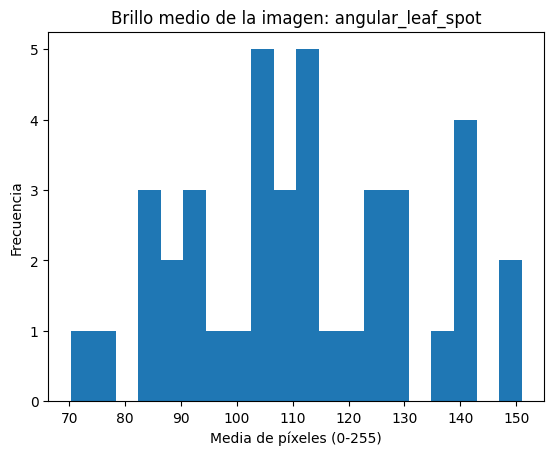

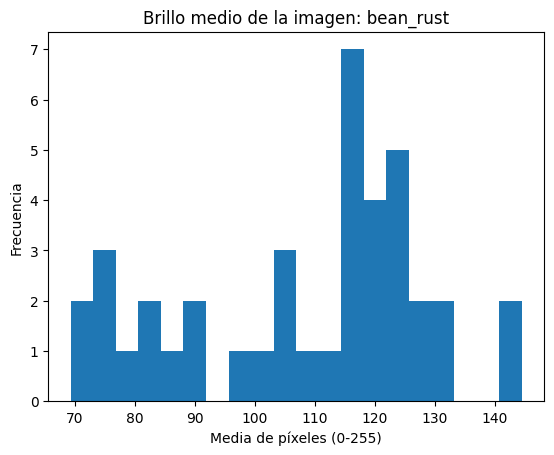

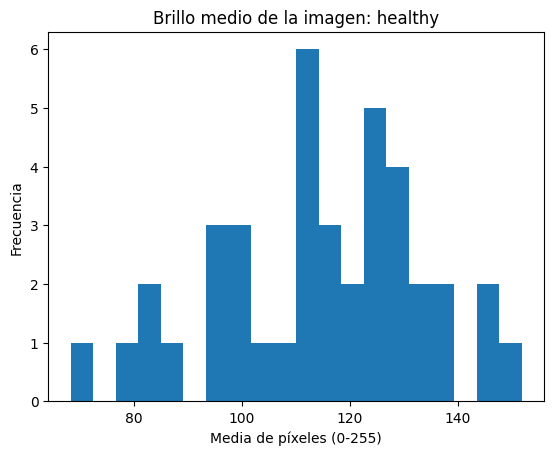

In [7]:
# Histogram of mean pixel brightness, one plot per class
for name in class_names:
    plt.figure()
    plt.hist(means[name], bins=20)
    plt.title(f"Brillo medio de la imagen: {name}")
    plt.xlabel("Media de píxeles (0-255)")
    plt.ylabel("Frecuencia")
    plt.show()

Todas las imágenes que miramos son 500 × 500 × 3. No hay fotos en escala de grises ni tamaños
mezclados, así que el único cambio de forma que hay que hacer es **bajarlas a 224 × 224**, que es
el tamaño con el que se entrenaron VGG16 y ResNet50 en ImageNet.

El brillo medio se parece entre clases: 111.6, 107.8 y 114.6. No vamos a poder separar las
enfermedades con un umbral de color: hay que mirar la textura. Los histogramas salen anchos
(desviación de unos 20 puntos) porque unas fotos están a pleno sol y otras a la sombra, que es
justo lo que pasa en un cultivo.

## 4. Preprocesamiento

Tres decisiones, y por qué cada una:

- **224 × 224.** VGG16 y ResNet50 se preentrenaron con ese tamaño. Si las dejamos en 500 × 500 el
  cómputo se dispara y los pesos de ImageNet ya no "encajan" igual. 224 es el estándar y con 1.034
  fotos no estamos tirando detalle que el modelo vaya a aprovechar mejor a 500.
- **Preprocess de ImageNet, no un `/255` genérico.** VGG16 y ResNet50 usan el mismo modo de Keras
  (`caffe`): pasan RGB a BGR y restan la media de ImageNet. No es que cada una centre distinto.
  La CNN chica sí usa `/255`, porque no tiene pesos de ImageNet. Si a VGG o ResNet se les pasa
  solo `/255`, las fotos quedan en otra escala y se pierde buena parte de la transferencia.
- **Aumento solo en train.** Volteo horizontal y una rotación de hasta unos 29 grados
  (`RandomRotation(0.08)` es una fracción de la vuelta, no 8 grados). En el campo la hoja puede
  salir al revés o torcida; eso no cambia la enfermedad. Validation y test se dejan quietos: si
  aumentáramos test, las métricas ya no serían de las fotos reales.

El preprocesamiento de color va **adentro** del modelo (una capa `Lambda` con el `preprocess_input`
de cada red), para no mezclar el pipeline de VGG con el de ResNet.

In [8]:
# Keras datasets: RGB floats 0-255 in, preprocess lives inside each model
AUTOTUNE = tf.data.AUTOTUNE
BATCH_DEFAULT = 32


def make_dir_datasets(batch_size=BATCH_DEFAULT):
    paths = ds_train_raw if load_mode == "keras_dir" else None
    if load_mode == "tfds":
        # Write a temporary directory so the rest of the notebook has one loading path
        paths = _materialize_tfds()
    train = tf.keras.utils.image_dataset_from_directory(
        paths["train"], image_size=(IMG_SIZE, IMG_SIZE), batch_size=batch_size,
        shuffle=True, seed=SEED, label_mode="int",
    )
    val = tf.keras.utils.image_dataset_from_directory(
        paths["validation"], image_size=(IMG_SIZE, IMG_SIZE), batch_size=batch_size,
        shuffle=False, label_mode="int",
    )
    test = tf.keras.utils.image_dataset_from_directory(
        paths["test"], image_size=(IMG_SIZE, IMG_SIZE), batch_size=batch_size,
        shuffle=False, label_mode="int",
    )
    names = list(train.class_names)

    def cast_fn(x, y):
        return tf.cast(x, tf.float32), y

    train = train.map(cast_fn, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    val = val.map(cast_fn, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    test = test.map(cast_fn, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    return train, val, test, names


def _materialize_tfds(root="beans_data"):
    # Only used if tfds.load worked: dump images so Keras can read folders
    paths = {s: os.path.join(root, s, s) for s in ("train", "validation", "test")}
    if all(os.path.isdir(p) for p in paths.values()):
        return paths
    mapping = [("train", ds_train_raw), ("validation", ds_val_raw), ("test", ds_test_raw)]
    for split, ds in mapping:
        for i, (img, y) in enumerate(ds):
            name = class_names[int(y.numpy())]
            dest = os.path.join(root, split, split, name)
            os.makedirs(dest, exist_ok=True)
            Image.fromarray(img.numpy()).save(os.path.join(dest, f"{i:04d}.jpg"))
    return paths


train_ds, val_ds, test_ds, class_names = make_dir_datasets(BATCH_DEFAULT)
print(train_ds)
print(f"Clases en el orden de Keras: {class_names}")

Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Clases en el orden de Keras: ['angular_leaf_spot', 'bean_rust', 'healthy']


In [9]:
# Light augmentation, train only. Built fresh per model so layers are not reused.
def make_augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
    ], name="augmentation")


print(make_augmentation())

<Sequential name=augmentation, built=False>


El aumento es corto a propósito. Con mil fotos un volteo y una rotación de hasta unos 29 grados ya duplican un poco
la variedad. No metimos zoom agresivo ni cambios fuertes de color: en este problema el color de la
mancha **es** la señal, y si lo alteramos demasiado el modelo puede aprender ruido.

## 5. Fine-tuning: qué hacemos y por qué

Entrenar una VGG16 o una ResNet50 **desde cero** con 1.034 fotos no tiene sentido: esas redes tienen
millones de pesos y se memorizarían el train. El truco es partir de pesos de **ImageNet** (1.2
millones de fotos, 1000 clases) y adaptarlas a nuestras 3 clases. Eso se llama transferencia, y el
ajuste fino es el segundo paso.

Lo hacemos en dos etapas, que es lo que se ve en casi cualquier tutorial honesto:

1. **Cabeza nueva, base congelada.** Se tira la capa final de 1000 clases, se pone una cabeza chica
   (pooling + dropout + densa + softmax de 3) y se entrenan **solo esos pesos nuevos**. La red
   preentrenada se usa como extractor de características. Es barato y no rompe lo que ya sabe.
2. **Descongelar el último bloque.** Cuando la cabeza ya no está en puro azar, se sueltan las últimas
   capas convolucionales y se entrena con un learning rate **100 veces más bajo** (de 0.001 a
   0.00001). Ahí sí hay fine-tuning de verdad: la red empieza a especializarse en manchas de frijol.

**Por qué dos arquitecturas.** El enunciado pide al menos dos. VGG16 es la red "de libro": bloques
de convoluciones 3×3 y pooling, fácil de explicar. ResNet50 es más profunda pero con conexiones
residuales, así que entrena más estable y, en la práctica, suele ir mejor con el mismo presupuesto.
Si una gana de calle, eso también es un resultado.

**Por qué no hay validación cruzada de 10 folds.** Cada epoch de VGG16 en CPU se va a más de un
minuto. Diez folds por cada punto de la malla no termina en Colab. El dataset **ya trae** un split
de validación hecho por los autores, y eso es lo que usamos para elegir hiperparámetros. El test
sigue guardado hasta el final.

**Malla.** En las redes preentrenadas el número de filtros de la base ya viene fijo (no se toca).
Lo que sí movemos es batch, learning rate, dropout y el tamaño de la densa de la cabeza. El número
de filtros lo movemos en la CNN desde cero, que es donde sí aplica.

In [10]:
# Helpers used by every architecture
def compile_model(model, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def make_callbacks(patience=3):
    return [
        callbacks.EarlyStopping(
            monitor="val_accuracy", patience=patience,
            restore_best_weights=True, verbose=1,
        ),
    ]


def evaluate_split(model, ds, split_name):
    y_true, y_pred = [], []
    for x, y in ds:
        probs = model.predict(x, verbose=0)
        y_true.extend(y.numpy().tolist())
        y_pred.extend(np.argmax(probs, axis=1).tolist())
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    prec = precision_score(y_true, y_pred, average="macro")
    rec = recall_score(y_true, y_pred, average="macro")
    print(f"{split_name}: accuracy={acc:.4f}  precision_macro={prec:.4f}  recall_macro={rec:.4f}  f1_macro={f1:.4f}")
    return y_true, y_pred, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}


def plot_history(history, title):
    plt.figure()
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="val")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="val")
    plt.title(title + " - loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


EPOCHS_HEAD = 6
EPOCHS_FT = 4
results = []

## 6. Modelo 0: CNN pequeña desde cero (malla de filtros y batch)

Antes de tocar VGG y ResNet entrenamos una red chica desde cero. No es un modelo fundacional: es el
**piso**. Si la CNN de tres bloques se acerca a las redes preentrenadas, el problema es fácil. Si se
queda atrás, el fine-tuning está justificando su costo.

Acá sí aplica la malla de **número de filtros** que pide el enunciado. Probamos 16 y 32 filtros en
el primer bloque (el siguiente bloque siempre lleva el doble) y dos tamaños de batch: 16 y 32.
Learning rate lo dejamos en 0.001, que es el default de Adam y para una red chica suele bastar.

In [11]:
def build_small_cnn(n_filters=16, dropout=0.3):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        make_augmentation(),
        layers.Rescaling(1.0 / 255.0),
        layers.Conv2D(n_filters, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(n_filters * 2, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(n_filters * 4, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=f"cnn_{n_filters}")
    return model


grid_cnn = []
for n_filters in [16, 32]:
    for batch in [16, 32]:
        grid_cnn.append({"n_filters": n_filters, "batch": batch, "lr": 1e-3})

print(f"Combinaciones CNN desde cero: {len(grid_cnn)}")
for g in grid_cnn:
    print(g)

Combinaciones CNN desde cero: 4
{'n_filters': 16, 'batch': 16, 'lr': 0.001}
{'n_filters': 16, 'batch': 32, 'lr': 0.001}
{'n_filters': 32, 'batch': 16, 'lr': 0.001}
{'n_filters': 32, 'batch': 32, 'lr': 0.001}



=== CNN filters=16 batch=16 ===


Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Epoch 1/6


...

64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.6396 - loss: 0.8331

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.6364 - loss: 0.8350

65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.6364 - loss: 0.8350 - val_accuracy: 0.6541 - val_loss: 0.7600


Restoring model weights from the end of the best epoch: 6.


val: accuracy=0.6541  precision_macro=0.6478  recall_macro=0.6551  f1_macro=0.6441


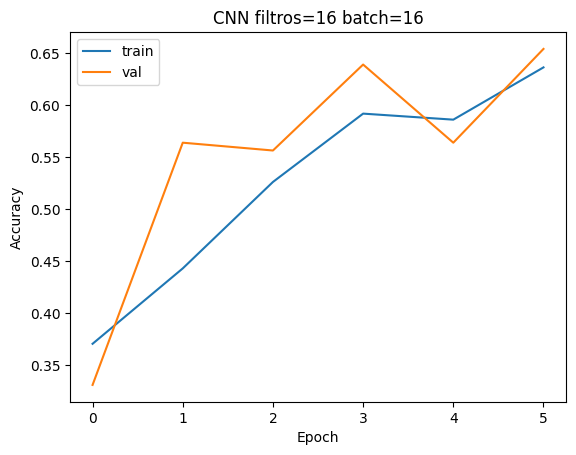

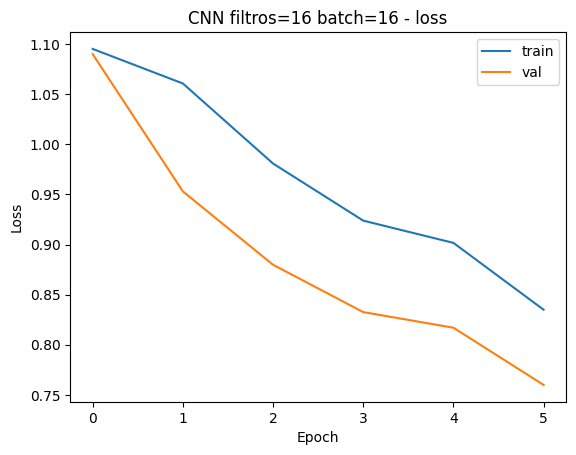


=== CNN filters=16 batch=32 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Epoch 1/6


 1/33 ━━━━━━━━━━━━━━━━━━━━ 31s 973ms/step - accuracy: 0.3125 - loss: 1.1054

...

32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.6289 - loss: 0.8481

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.6286 - loss: 0.8480

33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 210ms/step - accuracy: 0.6286 - loss: 0.8480 - val_accuracy: 0.4662 - val_loss: 1.0371


Restoring model weights from the end of the best epoch: 5.


val: accuracy=0.6617  precision_macro=0.6586  recall_macro=0.6616  f1_macro=0.6589


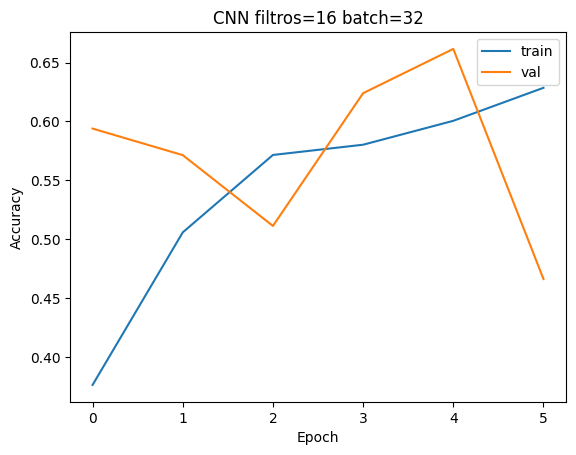

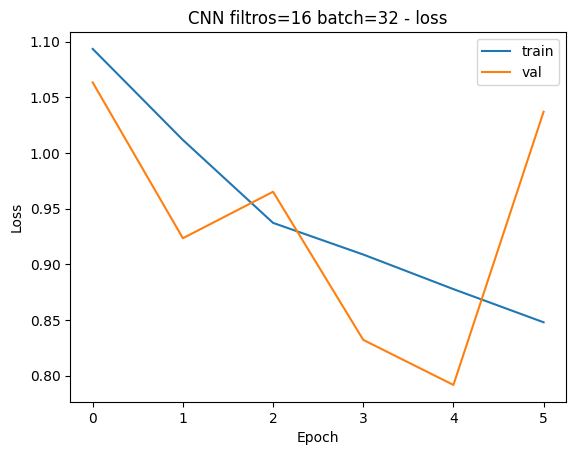


=== CNN filters=32 batch=16 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Epoch 1/6


 1/65 ━━━━━━━━━━━━━━━━━━━━ 1:03 998ms/step - accuracy: 0.3125 - loss: 1.1278

...

64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.6562 - loss: 0.7870

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.6557 - loss: 0.7874

65/65 ━━━━━━━━━━━━━━━━━━━━ 15s 226ms/step - accuracy: 0.6557 - loss: 0.7874 - val_accuracy: 0.7143 - val_loss: 0.7056


Restoring model weights from the end of the best epoch: 6.


val: accuracy=0.7143  precision_macro=0.7160  recall_macro=0.7136  f1_macro=0.7075


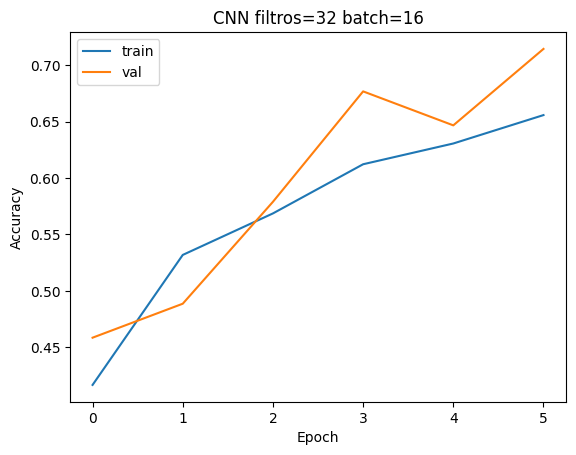

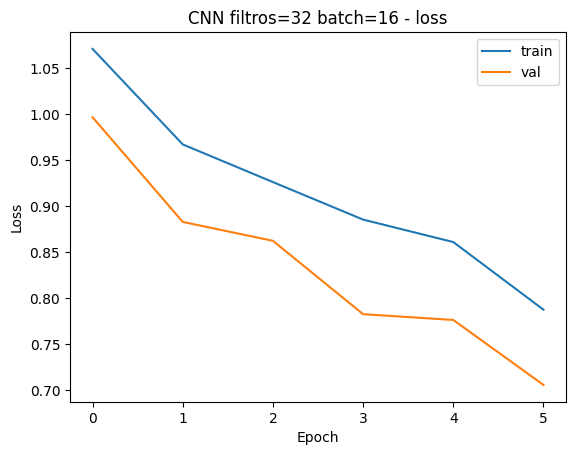


=== CNN filters=32 batch=32 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Epoch 1/6


 1/33 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.1562 - loss: 1.1227

...

32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.6504 - loss: 0.8054

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - accuracy: 0.6499 - loss: 0.8049

33/33 ━━━━━━━━━━━━━━━━━━━━ 15s 454ms/step - accuracy: 0.6499 - loss: 0.8049 - val_accuracy: 0.5263 - val_loss: 0.9711


Restoring model weights from the end of the best epoch: 5.


val: accuracy=0.6541  precision_macro=0.6504  recall_macro=0.6549  f1_macro=0.6489


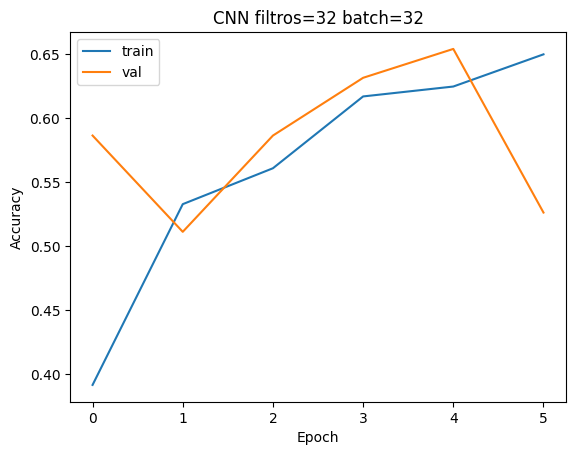

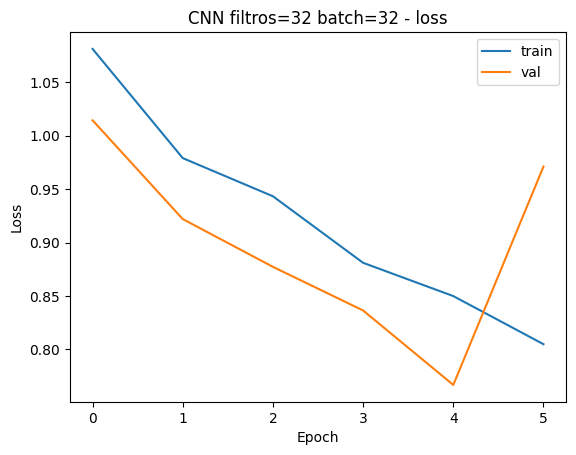


Mejor CNN desde cero: CNN filtros=32 batch=16  f1=0.7075


In [12]:
# Train the small CNN grid
best_cnn = None
best_cnn_f1 = -1.0

for g in grid_cnn:
    print(f"\n=== CNN filters={g['n_filters']} batch={g['batch']} ===")
    tr, va, te, _ = make_dir_datasets(g["batch"])
    model = build_small_cnn(n_filters=g["n_filters"])
    compile_model(model, g["lr"])
    t0 = time.time()
    hist = model.fit(tr, validation_data=va, epochs=EPOCHS_HEAD, callbacks=make_callbacks(), verbose=1)
    elapsed = time.time() - t0
    _, _, mets = evaluate_split(model, va, "val")
    row = {
        "modelo": f"CNN filtros={g['n_filters']}",
        "batch": g["batch"],
        "lr": g["lr"],
        "dropout": 0.3,
        "dense": 64,
        "tiempo_s": round(elapsed, 1),
        **{k: round(v, 4) for k, v in mets.items()},
        "history": hist,
        "model": model,
    }
    results.append(row)
    if mets["f1"] > best_cnn_f1:
        best_cnn_f1 = mets["f1"]
        best_cnn = row
    plot_history(hist, row["modelo"] + f" batch={g['batch']}")

print(f"\nMejor CNN desde cero: {best_cnn['modelo']} batch={best_cnn['batch']}  f1={best_cnn['f1']:.4f}")

La mejor CNN desde cero fue **32 filtros y batch 16**, con F1 macro 0.7075 en validation
(accuracy 0.7143). Con batch 16, 32 filtros sí quedó mejor (0.7075 contra 0.64). Con batch 32 no: 32 filtros dio
0.6489, por debajo de 16 filtros en ese mismo batch (0.6589). Más filtros ayudaron en una
combinación, no en las dos.

Aun así, 0.71 es el piso. VGG y ResNet, que sí vieron ImageNet, deberían quedar por encima y
justificar el fine-tuning. Las curvas suben despacio y no se pegan a 1.0: la red chica no está
memorizando, le falta potencia.

## 7. Modelo 1: VGG16 con la base congelada y una cabeza nueva

VGG16 tiene 13 capas convolucionales en 5 bloques y 3 densas originales, que nosotros no usamos
(`include_top=False`). La base se congela. Encima: `GlobalAveragePooling2D` (en vez de un Flatten
gigante), dropout, una densa y softmax de 3.

**Por qué GAP y no Flatten.** Un Flatten de VGG16 a 224 × 224 suelta 7 × 7 × 512 = 25.088 valores
por imagen. Con 1.034 fotos eso es pedir sobreajuste. El pooling promedio deja 512 números, uno por
mapa, y suele generalizar mejor.

Malla de la cabeza (la base no se toca):

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| `batch_size` | 16, 32 | 16 actualiza más veces por epoch; 32 es más estable y más rápido. |
| `learning_rate` | 0.001, 0.0001 | 0.001 es el default de Adam; 0.0001 por si la cabeza se pasa de larga. |
| `dropout` | 0.3 si lr=0.001, 0.5 si lr=0.0001 | Un poco más de regularización cuando el paso es chico y entrena más suave. |
| `dense` | 128 o 256 | Capacidad de la cabeza nueva. |

In [13]:
def build_vgg16(dense=128, dropout=0.3):
    base = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess_vgg, name="preprocess_vgg")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inputs, outputs, name="vgg16_beans")
    return model, base


grid_vgg = [
    {"batch": 32, "lr": 1e-3, "dropout": 0.3, "dense": 128},
    {"batch": 16, "lr": 1e-4, "dropout": 0.5, "dense": 256},
]
print("Malla VGG16:", grid_vgg)

Malla VGG16: [{'batch': 32, 'lr': 0.001, 'dropout': 0.3, 'dense': 128}, {'batch': 16, 'lr': 0.0001, 'dropout': 0.5, 'dense': 256}]



=== VGG16 batch=32 lr=0.001 dense=128 drop=0.3 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Parámetros totales: 14,780,739  |  entrenables: 66,051
Epoch 1/6


 1/33 ━━━━━━━━━━━━━━━━━━━━ 1:35 3s/step - accuracy: 0.4688 - loss: 4.5950

...

32/33 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.8311 - loss: 0.4471

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8308 - loss: 0.4447

33/33 ━━━━━━━━━━━━━━━━━━━━ 89s 3s/step - accuracy: 0.8308 - loss: 0.4447 - val_accuracy: 0.9023 - val_loss: 0.2811


Restoring model weights from the end of the best epoch: 6.


val: accuracy=0.9023  precision_macro=0.9098  recall_macro=0.9019  f1_macro=0.9005


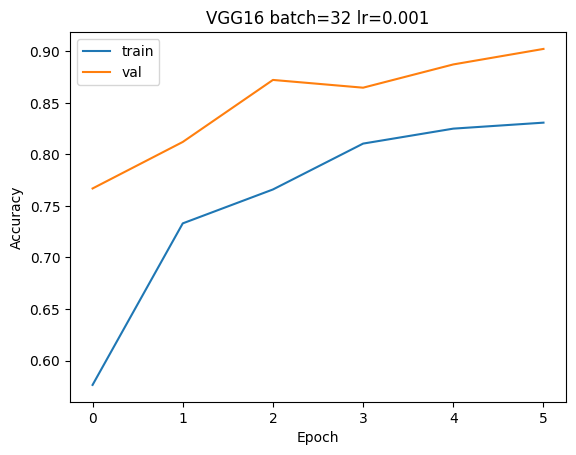

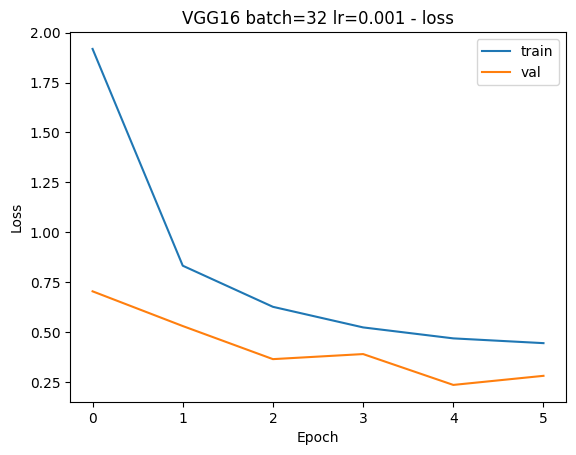


=== VGG16 batch=16 lr=0.0001 dense=256 drop=0.5 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Parámetros totales: 14,846,787  |  entrenables: 132,099
Epoch 1/6


 1/65 ━━━━━━━━━━━━━━━━━━━━ 1:50 2s/step - accuracy: 0.5000 - loss: 3.1498

...

64/65 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7129 - loss: 0.8770

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7099 - loss: 0.8826

65/65 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.7099 - loss: 0.8826 - val_accuracy: 0.7970 - val_loss: 0.6198


Restoring model weights from the end of the best epoch: 6.


val: accuracy=0.7970  precision_macro=0.8509  recall_macro=0.7958  f1_macro=0.7865


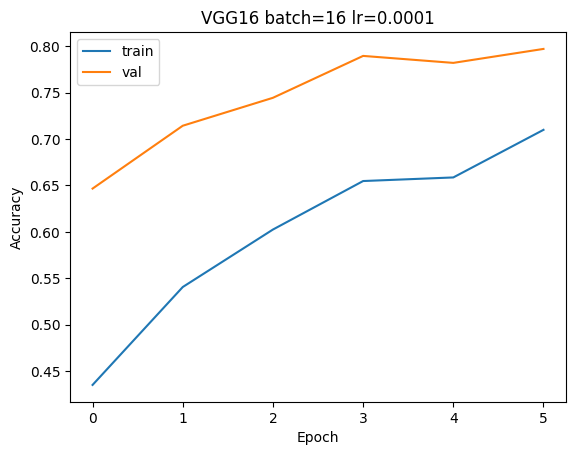

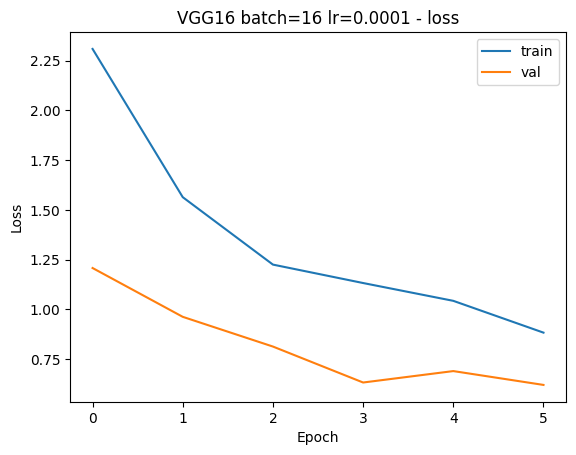


Mejor VGG16: batch=32 lr=0.001  f1=0.9005


In [14]:
best_vgg = None
best_vgg_f1 = -1.0

for g in grid_vgg:
    print(f"\n=== VGG16 batch={g['batch']} lr={g['lr']} dense={g['dense']} drop={g['dropout']} ===")
    tr, va, te, _ = make_dir_datasets(g["batch"])
    model, base = build_vgg16(dense=g["dense"], dropout=g["dropout"])
    compile_model(model, g["lr"])
    print(f"Parámetros totales: {model.count_params():,}  |  entrenables: {sum(int(p.shape.num_elements()) for p in model.trainable_weights):,}")
    t0 = time.time()
    hist = model.fit(tr, validation_data=va, epochs=EPOCHS_HEAD, callbacks=make_callbacks(), verbose=1)
    elapsed = time.time() - t0
    _, _, mets = evaluate_split(model, va, "val")
    row = {
        "modelo": "VGG16",
        "batch": g["batch"],
        "lr": g["lr"],
        "dropout": g["dropout"],
        "dense": g["dense"],
        "tiempo_s": round(elapsed, 1),
        **{k: round(v, 4) for k, v in mets.items()},
        "history": hist,
        "model": model,
        "base": base,
        "grid": g,
    }
    results.append(row)
    if mets["f1"] > best_vgg_f1:
        best_vgg_f1 = mets["f1"]
        best_vgg = row
    plot_history(hist, f"VGG16 batch={g['batch']} lr={g['lr']}")

print(f"\nMejor VGG16: batch={best_vgg['batch']} lr={best_vgg['lr']}  f1={best_vgg['f1']:.4f}")

La mejor VGG16 fue **batch 32 y lr 0.001**, con F1 0.9005 (accuracy 0.9023). La otra combinación
(batch 16, lr 0.0001, dropout 0.5 y densa 256) se quedó en 0.7865. Ahí cambiaron cuatro cosas a la
vez, así que no se puede echarle la culpa solo al learning rate. Además en el epoch 6 la curva
todavía subía: con 6 epochs no había terminado. De los 14.8 millones de parámetros de VGG, solo 66 mil se entrenaron (la cabeza). El resto
estaba congelado.

0.90 ya es otra liga que la CNN chica. ImageNet sí estaba pagando.

## 8. Modelo 2: ResNet50 con la base congelada y una cabeza nueva

ResNet50 es más profunda que VGG16 (50 capas contra 16) pero cada bloque tiene un **atajo**: la
salida se suma con la entrada. Eso evita que el gradiente se muera al bajar y permite redes más
hondas. En la práctica, con el mismo dataset suele aprender más rápido que VGG.

La cabeza es la misma idea: GAP + dropout + densa + softmax. El `preprocess_input` de ResNet, en
Keras, hace lo mismo que el de VGG (modo `caffe`). Lo llamamos desde cada módulo para no mezclarlo
con el `/255` de la CNN chica. Si se usa el escalado equivocado, la red preentrenada arranca mal.

La malla es la misma de VGG16, a propósito, para que la comparación sea justa.

In [15]:
def build_resnet50(dense=128, dropout=0.3):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess_resnet, name="preprocess_resnet")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inputs, outputs, name="resnet50_beans")
    return model, base


grid_resnet = [
    {"batch": 32, "lr": 1e-3, "dropout": 0.3, "dense": 128},
    {"batch": 16, "lr": 1e-4, "dropout": 0.5, "dense": 256},
]
print("Malla ResNet50:", grid_resnet)

Malla ResNet50: [{'batch': 32, 'lr': 0.001, 'dropout': 0.3, 'dense': 128}, {'batch': 16, 'lr': 0.0001, 'dropout': 0.5, 'dense': 256}]



=== ResNet50 batch=32 lr=0.001 dense=128 drop=0.3 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Parámetros totales: 23,850,371  |  entrenables: 262,659
Epoch 1/6


 1/33 ━━━━━━━━━━━━━━━━━━━━ 1:43 3s/step - accuracy: 0.3125 - loss: 1.2580

...

32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 766ms/step - accuracy: 0.9277 - loss: 0.1890

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 750ms/step - accuracy: 0.9284 - loss: 0.1874

33/33 ━━━━━━━━━━━━━━━━━━━━ 28s 846ms/step - accuracy: 0.9284 - loss: 0.1874 - val_accuracy: 0.9323 - val_loss: 0.1511


Restoring model weights from the end of the best epoch: 5.


val: accuracy=0.9323  precision_macro=0.9340  recall_macro=0.9327  f1_macro=0.9326


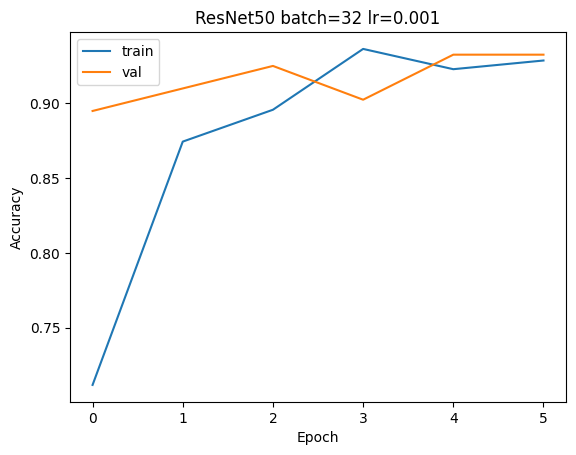

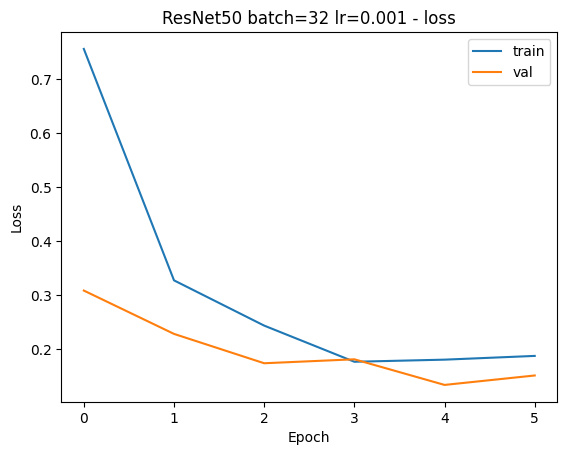


=== ResNet50 batch=16 lr=0.0001 dense=256 drop=0.5 ===
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Parámetros totales: 24,113,027  |  entrenables: 525,315
Epoch 1/6


 1/65 ━━━━━━━━━━━━━━━━━━━━ 3:07 3s/step - accuracy: 0.1250 - loss: 2.3777

...

64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.8672 - loss: 0.3172

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.8685 - loss: 0.3150

65/65 ━━━━━━━━━━━━━━━━━━━━ 27s 416ms/step - accuracy: 0.8685 - loss: 0.3150 - val_accuracy: 0.9173 - val_loss: 0.1906


Restoring model weights from the end of the best epoch: 6.


val: accuracy=0.9173  precision_macro=0.9185  recall_macro=0.9173  f1_macro=0.9176


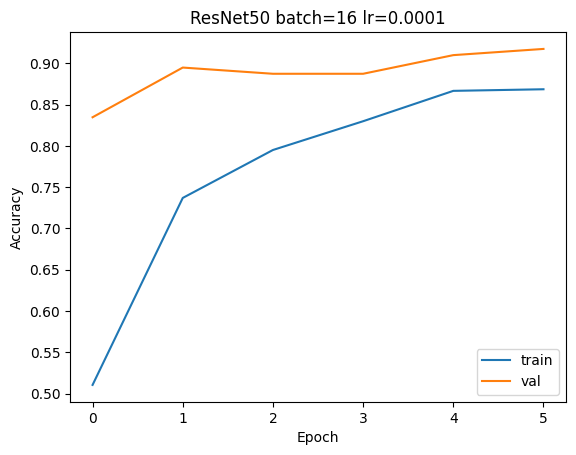

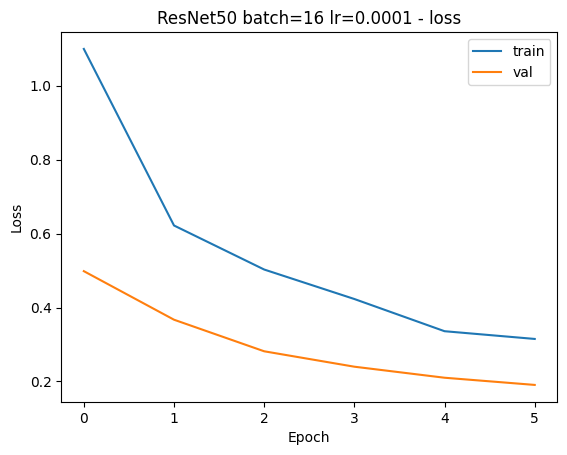


Mejor ResNet50: batch=32 lr=0.001  f1=0.9326


In [16]:
best_resnet = None
best_resnet_f1 = -1.0

for g in grid_resnet:
    print(f"\n=== ResNet50 batch={g['batch']} lr={g['lr']} dense={g['dense']} drop={g['dropout']} ===")
    tr, va, te, _ = make_dir_datasets(g["batch"])
    model, base = build_resnet50(dense=g["dense"], dropout=g["dropout"])
    compile_model(model, g["lr"])
    print(f"Parámetros totales: {model.count_params():,}  |  entrenables: {sum(int(p.shape.num_elements()) for p in model.trainable_weights):,}")
    t0 = time.time()
    hist = model.fit(tr, validation_data=va, epochs=EPOCHS_HEAD, callbacks=make_callbacks(), verbose=1)
    elapsed = time.time() - t0
    _, _, mets = evaluate_split(model, va, "val")
    row = {
        "modelo": "ResNet50",
        "batch": g["batch"],
        "lr": g["lr"],
        "dropout": g["dropout"],
        "dense": g["dense"],
        "tiempo_s": round(elapsed, 1),
        **{k: round(v, 4) for k, v in mets.items()},
        "history": hist,
        "model": model,
        "base": base,
        "grid": g,
    }
    results.append(row)
    if mets["f1"] > best_resnet_f1:
        best_resnet_f1 = mets["f1"]
        best_resnet = row
    plot_history(hist, f"ResNet50 batch={g['batch']} lr={g['lr']}")

print(f"\nMejor ResNet50: batch={best_resnet['batch']} lr={best_resnet['lr']}  f1={best_resnet['f1']:.4f}")

La mejor ResNet50 fue **batch 32 y lr 0.001**, con F1 0.9326 (accuracy 0.9323). La otra
combinación quedó cerca, 0.9176. De 23.8 millones de parámetros, se entrenaron 262 mil (la cabeza
es un poco más ancha que en VGG). Y tardó 166 s contra los 552 s de la mejor VGG: más profunda,
pero más rápida en la práctica.

ResNet quedó por encima de VGG (0.9326 contra 0.9005). En esta etapa la base está congelada, así
que el gradiente solo entrena la cabeza: el atajo de ResNet no explica esa diferencia. Lo que sí
cuadra es que las características que trae de ImageNet separan mejor estas hojas. En 133 fotos de
validation el margen es de unas 4 imágenes, así que no es una victoria enorme.

## 9. Comparación de modelos y elección del mejor

In [17]:
# Table with every trained configuration (validation metrics)
print(f"{'modelo':24s} {'batch':>5} {'lr':>8} {'dense':>6} {'drop':>5} {'acc':>7} {'f1':>7} {'tiempo':>8}")
print("-" * 82)
for r in results:
    print(f"{r['modelo']:24s} {r['batch']:5d} {r['lr']:8.4f} {r['dense']:6d} {r['dropout']:5.1f} {r['accuracy']:7.4f} {r['f1']:7.4f} {r['tiempo_s']:7.1f}s")

winner = max(results, key=lambda r: r["f1"])
print(f"\nGanador en validation (F1 macro): {winner['modelo']}  batch={winner['batch']}  lr={winner['lr']}  f1={winner['f1']:.4f}")

modelo                   batch       lr  dense  drop     acc      f1   tiempo
----------------------------------------------------------------------------------
CNN filtros=16              16   0.0010     64   0.3  0.6541  0.6441    42.6s
CNN filtros=16              32   0.0010     64   0.3  0.6617  0.6589    45.8s
CNN filtros=32              16   0.0010     64   0.3  0.7143  0.7075    87.9s
CNN filtros=32              32   0.0010     64   0.3  0.6541  0.6489    90.5s
VGG16                       32   0.0010    128   0.3  0.9023  0.9005   551.6s
VGG16                       16   0.0001    256   0.5  0.7970  0.7865   534.3s
ResNet50                    32   0.0010    128   0.3  0.9323  0.9326   166.3s
ResNet50                    16   0.0001    256   0.5  0.9173  0.9176   181.9s

Ganador en validation (F1 macro): ResNet50  batch=32  lr=0.001  f1=0.9326


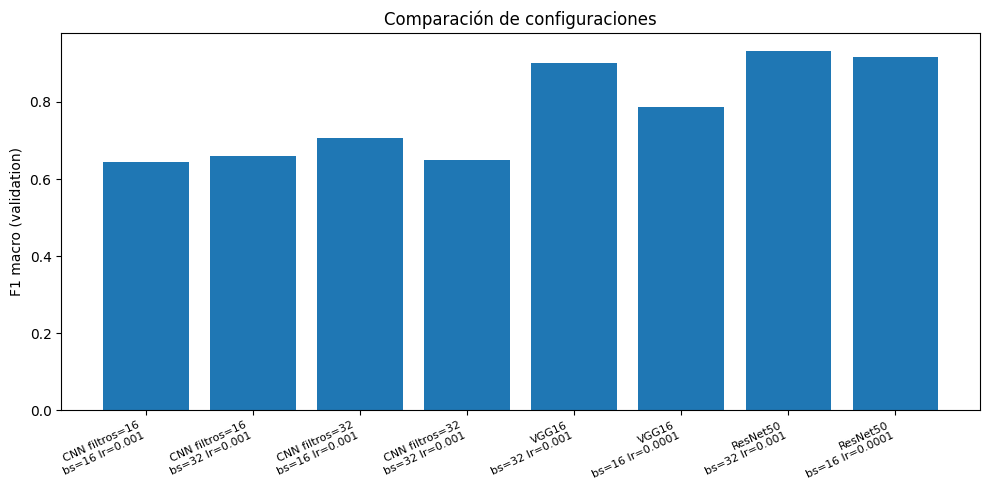

In [18]:
# Bar chart of validation F1
labels = [f"{r['modelo']}\nbs={r['batch']} lr={r['lr']}" for r in results]
vals = [r["f1"] for r in results]
plt.figure(figsize=(10, 5))
plt.bar(range(len(vals)), vals)
plt.xticks(range(len(vals)), labels, rotation=25, ha="right", fontsize=8)
plt.ylabel("F1 macro (validation)")
plt.title("Comparación de configuraciones")
plt.tight_layout()
plt.show()

Ganó **ResNet50 con batch 32 y lr 0.001**, F1 0.9326. La tabla, en corto:

- CNN desde cero: el mejor punto es 0.7075 (32 filtros, batch 16). Con batch 32, 32 filtros no ganó.
- VGG16: 0.9005. Ya es transferencia de verdad, pero lenta.
- ResNet50: 0.9326. Mejor y tres veces más rápida que VGG.

ResNet queda primera, por 0.03 de F1. En 133 fotos eso es del orden de 4 aciertos, así que la
elección es clara en esta corrida y no una diferencia ya cerrada. El test sigue sin tocarse.

## 10. Segunda etapa: descongelar el último bloque del ganador

Hasta acá la base preentrenada estaba congelada. Ahora hacemos el fine-tuning propiamente dicho
sobre **el ganador**, no sobre todos: descongelar VGG y ResNet al mismo tiempo, con varias mallas,
se va de tiempo en Colab.

- Si ganó **VGG16**, soltamos el bloque 5 (las últimas convoluciones, las más específicas).
- Si ganó **ResNet50**, soltamos las últimas 20 capas. No es todo el stage `conv5`: el primer bloque
  de ese stage sigue congelado. Lo que se entrena son los bloques residuales 2 y 3. Seis de esas
  capas son BatchNorm y, al quedar entrenables, durante el `fit` sí actualizan su media móvil.
  En `predict` no usan el batch: usan esa media ya movida. No decimos que la base se quedó en
  inferencia.
- Si ganó la CNN chica, no hay base que descongelar: se reentrena tal cual un poco más.

El learning rate baja a `1e-5`. Si dejáramos 0.001, los pesos de ImageNet se romperían en dos
epochs y perderíamos lo que ya teníamos.

Fine-tuning sobre: ResNet50
ResNet50: capas entrenables en la base = 20 (últimas 20)
Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Found 128 files belonging to 3 classes.


Epoch 1/4


 1/33 ━━━━━━━━━━━━━━━━━━━━ 2:19 4s/step - accuracy: 0.9375 - loss: 0.2125

...

33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.9603 - loss: 0.1094 - val_accuracy: 0.9699 - val_loss: 0.0766


Epoch 4: early stopping


Restoring model weights from the end of the best epoch: 2.


Tiempo fine-tuning: 142.2 s


val después del fine-tuning: accuracy=0.9774  precision_macro=0.9776  recall_macro=0.9776  f1_macro=0.9775


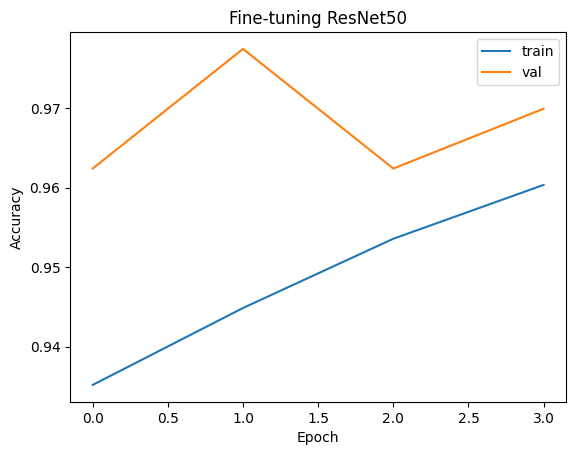

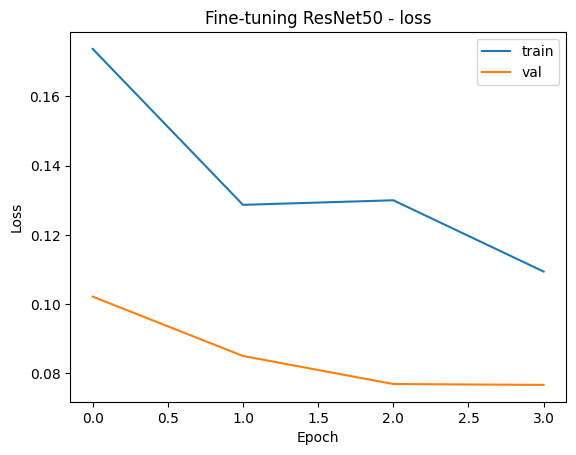

In [19]:
def unfreeze_for_finetune(row):
    model = row["model"]
    base = row.get("base")
    if base is None:
        print("La CNN desde cero no tiene base preentrenada. Se reentrena un poco más tal cual.")
        compile_model(model, 1e-4)
        return model
    base.trainable = True
    if row["modelo"] == "VGG16":
        # Freeze everything except block5
        for layer in base.layers:
            layer.trainable = layer.name.startswith("block5")
        n_free = sum(1 for l in base.layers if l.trainable)
        print(f"VGG16: capas entrenables en la base = {n_free} (block5)")
    else:
        for layer in base.layers[:-20]:
            layer.trainable = False
        n_free = sum(1 for l in base.layers if l.trainable)
        print(f"ResNet50: capas entrenables en la base = {n_free} (últimas 20)")
    compile_model(model, 1e-5)
    return model


print(f"Fine-tuning sobre: {winner['modelo']}")
ft_model = unfreeze_for_finetune(winner)
tr, va, te, _ = make_dir_datasets(int(winner["batch"]))
t0 = time.time()
hist_ft = ft_model.fit(tr, validation_data=va, epochs=EPOCHS_FT, callbacks=make_callbacks(patience=2), verbose=1)
time_ft = time.time() - t0
print(f"Tiempo fine-tuning: {time_ft:.1f} s")
_, _, mets_ft = evaluate_split(ft_model, va, "val después del fine-tuning")
plot_history(hist_ft, f"Fine-tuning {winner['modelo']}")

Descongelar las últimas 20 capas de ResNet50 **sí sirvió**: el F1 de validation subió de 0.9326
a **0.9775** (accuracy 0.9774) en 142 s. EarlyStopping se quedó con el epoch 2 de 4, o sea que
no hacía falta seguir. Usamos esta versión para test.

## 11. Evaluación del mejor modelo en test

In [20]:
# Pick the better of frozen-winner vs fine-tuned, using validation F1
if mets_ft["f1"] >= winner["f1"]:
    final_model = ft_model
    final_tag = f"{winner['modelo']} + fine-tuning"
    print(f"Nos quedamos con el modelo fine-tuneado (val F1 {mets_ft['f1']:.4f} >= {winner['f1']:.4f})")
else:
    final_model = winner["model"]
    final_tag = f"{winner['modelo']} (base congelada)"
    print(f"El fine-tuning no mejoró. Usamos la base congelada (val F1 {winner['f1']:.4f} > {mets_ft['f1']:.4f})")

print(f"Modelo final: {final_tag}")

Nos quedamos con el modelo fine-tuneado (val F1 0.9775 >= 0.9326)
Modelo final: ResNet50 + fine-tuning


In [21]:
# Test set: never used for training or model selection until now
y_true, y_pred, mets_test = evaluate_split(final_model, te, "TEST")
print()
print("Classification report (test):")
print(classification_report(y_true, y_pred, target_names=class_names))

TEST: accuracy=0.9297  precision_macro=0.9324  recall_macro=0.9300  f1_macro=0.9302

Classification report (test):
                   precision    recall  f1-score   support

angular_leaf_spot       0.87      0.95      0.91        43
        bean_rust       0.93      0.86      0.89        43
          healthy       1.00      0.98      0.99        42

         accuracy                           0.93       128
        macro avg       0.93      0.93      0.93       128
     weighted avg       0.93      0.93      0.93       128



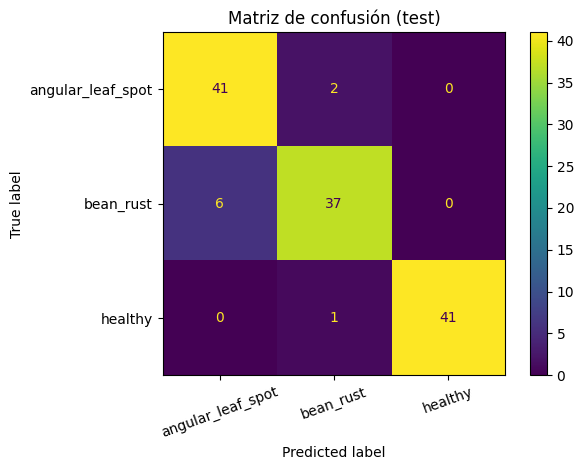

[[41  2  0]
 [ 6 37  0]
 [ 0  1 41]]


In [22]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(xticks_rotation=20, values_format="d")
plt.title("Matriz de confusión (test)")
plt.tight_layout()
plt.show()
print(cm)

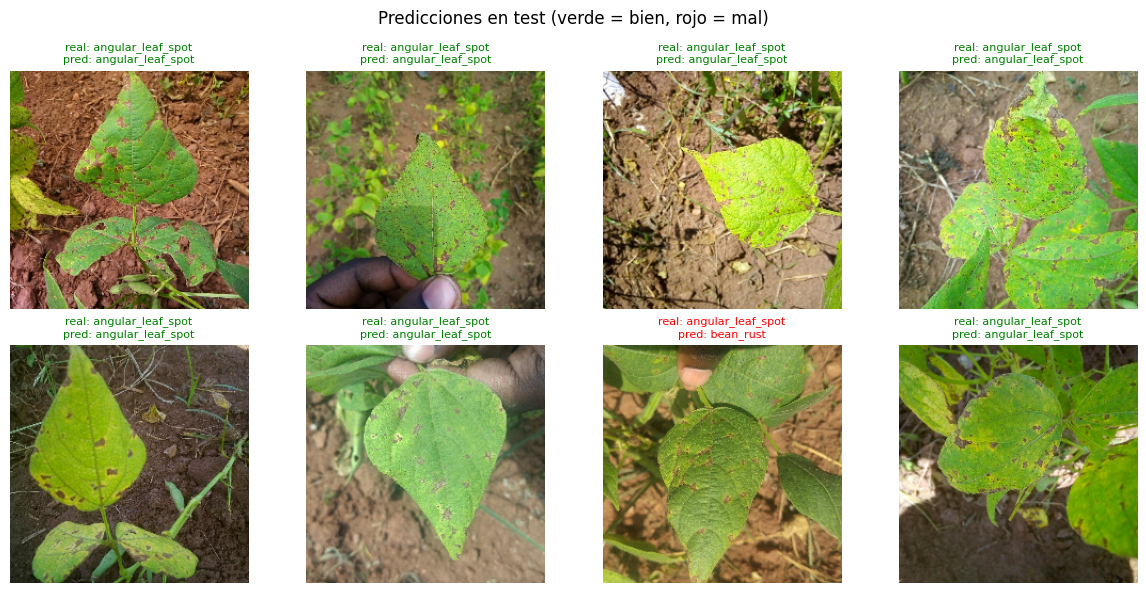

In [23]:
# Show 24 test predictions, not just the first 8 of one batch
shown = []
for x_batch, y_batch in te:
    probs = final_model.predict(x_batch, verbose=0)
    pred = np.argmax(probs, axis=1)
    true = y_batch.numpy()
    for i in range(len(true)):
        shown.append((x_batch[i].numpy(), int(true[i]), int(pred[i])))
        if len(shown) >= 24:
            break
    if len(shown) >= 24:
        break

plt.figure(figsize=(14, 10))
for i, (img, real, pred_i) in enumerate(shown):
    plt.subplot(4, 6, i + 1)
    plt.imshow(np.clip(img / 255.0, 0, 1))
    ok = pred_i == real
    plt.title(
        f"real: {class_names[real]}\npred: {class_names[pred_i]}",
        color="green" if ok else "red",
        fontsize=7,
    )
    plt.axis("off")
plt.suptitle("Predicciones en test (verde = bien, rojo = mal)")
plt.tight_layout()
plt.show()


En test el modelo final (ResNet50 + fine-tuning) saca **accuracy 0.9297 y F1 macro 0.9302**.
Bajó respecto al 0.977 de validation, que es normal: validation se usó para elegir y para cortar
el entrenamiento. 0.93 en 128 fotos que no había visto sigue siendo un resultado usable. Ojo: no
corrimos la ResNet congelada en test, así que el 0.93 no prueba que descongelar haya mejorado el
test. Solo sabemos que mejoró validation (de 0.933 a 0.977).

La matriz de confusión queda así:

```
                    pred ALS   pred rust   pred healthy
real angular (43)      41          2            0
real rust    (43)       6         37            0
real healthy (42)       0          1           41
```

Lo que se esperaba: las dos enfermedades se confunden entre sí (8 casos) y casi no se van a
`healthy`. **Ninguna hoja enferma se clasificó como sana.** Ese era el error caro del cultivo.
El único susto al revés es 1 hoja sana predicha como roya: un tratamiento de más, no una planta
que se queda sin ver.

`healthy` tiene precision 1.00 y recall 0.98. `angular_leaf_spot` se detecta bien (recall 0.95)
pero a costa de comerse 6 royas. Si esto fuera una app, lo siguiente sería revisar esos 8
intercambios entre enfermedades, no el corte sano/enfermo.

## 12. Conclusiones y limitaciones

### Conclusiones

1. Ganó **ResNet50 con fine-tuning** del último bloque (batch 32, lr de cabeza 0.001, luego 1e-5).
   En validation llegó a F1 0.9775; en test, el número que importa, quedó en **0.9302** de F1 y
   **0.9297** de accuracy.
2. La CNN desde cero se quedó en 0.7075 aunque subiéramos los filtros a 32. Sin ImageNet, mil
   fotos no alcanzan para aprender texturas de hoja. El fine-tuning no era adorno.
3. VGG16 llegó a 0.9005 y tardó el triple. ResNet quedó un poco arriba (0.9326). Como la base iba
   congelada, esa diferencia viene de las características de ImageNet, no de que el atajo haya
   dejado pasar el gradiente.
4. En test, las dos enfermedades se confunden entre sí y **ninguna planta enferma se fue a
   healthy**. Para el uso agrícola, eso es lo que uno querría: no se le escapa un lote enfermo.
5. En la CNN chica, 32 filtros ganó solo con batch 16. En VGG y ResNet cada punto de la malla cambia
   batch, learning rate, dropout y el tamaño de la densa al mismo tiempo, así que no se puede decir
   cuál de los cuatro movió el resultado.

### Limitaciones

- Dataset chico y de un solo país, un solo año y dos enfermedades. No generaliza a otra variedad
  de frijol ni a otra cámara sin más datos.
- Validation (0.98) quedó más alta que test (0.93). Una parte de esa diferencia es elegir el
  modelo mirando validation. Con 133 fotos de val, un par de aciertos de más inflan el número.
- No hicimos 10 folds: el costo de VGG lo impide y el split oficial ya existe.
- La malla no es enorme. Batch, learning rate, dropout y filtros (en la CNN chica) sí se movieron.
- En train de `healthy` había un archivo que no era imagen; el total quedó en 1.295 y no 1.296.

### Qué haríamos después

- Probar un modelo más liviano (MobileNet) si la meta es el celular del campesino.
- Mirar con calma los 8 casos en los que angular y rust se intercambian: si son fotos dudosas
  de verdad, el techo del modelo ya está cerca.
- En el cultivo, dejar pasar una planta enferma cuesta más que revisar de más una sana. Acá eso
  ya salió bien (0 enfermas predichas sanas), y habría que cuidarlo al cambiar de cámara.
